# Ephris vs. trained GCN and GAT

Compare **ROC-AUC for binary classification** and **accuracy for multiclass
classification** on the same query nodes. GCN and GAT train on the context labels
supplied to Ephris; Ephris uses its pretrained weights.

Datasets: Cornell (web pages), Reed98 (friendships), Cora (citations), and
[CityNetwork Paris](https://github.com/LeonResearch/City-Networks) (road junctions).
Paris uses the full 114,127-node graph, 37 augmented features and ten accessibility
classes. A CUDA GPU is recommended for the full comparison.

From a checkout, use CPython 3.11–3.14 on Linux:
```bash
python -m pip install '.[notebook]'
python -m jupyterlab examples/inference_demo.ipynb
```
Model weights download automatically on the first prediction; no Hugging Face
login is required. Use the same environment's kernel.
[Installation](../README.md#installation) · [Inference details](../docs/inference.md) ·
[Model license](https://huggingface.co/nums-ai/ephris/blob/main/LICENSE).


In [1]:
from pathlib import Path
import csv
import gc
import warnings

import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch_geometric.datasets import CityNetwork, LINKXDataset, Planetoid, WebKB
from torch_geometric.nn import GATConv, GCNConv
from torch_geometric.utils import add_self_loops, coalesce, remove_self_loops, to_undirected
from sklearn.metrics import accuracy_score, roc_auc_score
from IPython.display import Markdown, display
import matplotlib.pyplot as plt

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*torch.jit.script.*", category=DeprecationWarning)
    from ephris import EphrisClassifier

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/ephris").is_dir())
DATASETS = ("cornell", "reed98", "cora", "paris")
SEED = 42
CONTEXT_RATIO = 0.5
GNN_EPOCHS = 200
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

## 1. Load graphs and choose context nodes

For each class, a seeded random split assigns 50% of labeled nodes to context and
the remainder to queries. All methods receive the full graph, with undirected
edges and self-loops. Unknown labels are excluded from both sets. Only context
labels enter prediction or GNN training; query labels are used for scoring.

In [2]:
catalog = {
    "cornell": ("Cornell", WebKB, "Cornell"),
    "reed98": ("Reed98", LINKXDataset, "reed98"),
    "cora": ("Cora", Planetoid, "Cora"),
    "paris": ("Paris", CityNetwork, "paris"),
}


def make_task(name, graph):
    original = graph.y.view(-1).long()
    labeled = (original >= 0).nonzero(as_tuple=True)[0]
    classes, encoded = original[labeled].unique(sorted=True, return_inverse=True)
    y = torch.full_like(original, -1)
    y[labeled] = encoded
    context = []
    generator = torch.Generator().manual_seed(SEED)
    for label in range(len(classes)):
        nodes = (y == label).nonzero(as_tuple=True)[0]
        nodes = nodes[torch.randperm(len(nodes), generator=generator)]
        count = max(1, min(len(nodes) - 1, int(len(nodes) * CONTEXT_RATIO)))
        context.append(nodes[:count])
    context_indices = torch.cat(context).sort().values
    query_mask = y >= 0
    query_mask[context_indices] = False
    edges, _ = remove_self_loops(graph.edge_index)
    edges = to_undirected(coalesce(edges), num_nodes=graph.num_nodes)
    edges, _ = add_self_loops(edges, num_nodes=graph.num_nodes)
    return dict(name=name, x=graph.x.float(), edge_index=edges, classes=len(classes),
                context_indices=context_indices, context_labels=y[context_indices],
                query_indices=query_mask.nonzero(as_tuple=True)[0], query_labels=y[query_mask])


tasks = []
for key in DATASETS:
    name, loader, subset = catalog[key]
    graph = loader(str(ROOT / "data/notebook" / key), subset)[0]
    tasks.append(make_task(name, graph))

## 2. Train the two GNN baselines

Both baselines have two layers, 64 hidden channels and dropout 0.5. GAT uses four
attention heads in its first layer. Each model trains for 200 epochs with Adam
(learning rate 0.01, weight decay 0.0005), using context labels only. GNN features
are row-normalized; Ephris applies its pretrained preprocessing. Settings are
fixed in advance, with no query-label tuning or checkpoint selection.

In [3]:
class ContextGNN(nn.Module):
    def __init__(self, kind, features, classes):
        super().__init__()
        self.kind = kind
        if kind == "GCN":
            self.first = GCNConv(features, 64, cached=True, add_self_loops=False)
            self.second = GCNConv(64, classes, cached=True, add_self_loops=False)
        else:
            self.first = GATConv(features, 16, heads=4, dropout=0.5, add_self_loops=False)
            self.second = GATConv(64, classes, heads=1, concat=False, dropout=0.5,
                                  add_self_loops=False)

    def forward(self, x, edges):
        x = self.first(F.dropout(x, p=0.5, training=self.training), edges)
        x = F.elu(x) if self.kind == "GAT" else F.relu(x)
        return self.second(F.dropout(x, p=0.5, training=self.training), edges)


def fit_gnn(kind, x, edge_index, context_indices, context_labels, classes):
    torch.manual_seed(SEED)
    features = F.normalize(x.to(device), p=1, dim=1)
    edges = edge_index.to(device)
    indices, labels = context_indices.to(device), context_labels.to(device)
    if labels.numel() != indices.numel():
        raise ValueError("One label per context node is required")
    model = ContextGNN(kind, features.shape[1], classes).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    model.train()
    for _ in range(GNN_EPOCHS):
        optimizer.zero_grad(set_to_none=True)
        loss = F.cross_entropy(model(features, edges)[indices], labels)
        loss.backward()
        optimizer.step()
    model.eval()
    with torch.inference_mode():
        return model(features, edges).softmax(-1).cpu()

## 3. Compare query-node performance

Ephris runs once per graph. GCN and GAT each train once and then predict.
Binary tasks use the positive-class probability for ROC-AUC; multiclass tasks
use the predicted label for accuracy. This is an illustrative comparison on
one fixed split, using simple GNN baselines.

In [4]:
def score(truth, probabilities):
    if probabilities.shape[1] == 2:
        return "ROC-AUC", float(roc_auc_score(truth.numpy(), probabilities[:, 1].numpy()))
    return "Accuracy", float(accuracy_score(truth.numpy(), probabilities.argmax(1).numpy()))


summary = []
for task in tasks:
    model = EphrisClassifier(device=str(device), random_state=SEED)
    probabilities = model.predict_proba(
        task["x"], task["edge_index"],
        context_indices=task["context_indices"], context_labels=task["context_labels"],
    )
    assert model.classes_.tolist() == list(range(task["classes"]))
    metric, value = score(task["query_labels"], probabilities[task["query_indices"]])
    row = dict(Dataset=task["name"], Nodes=len(task["x"]), Metric=metric, Ephris=value)
    del model, probabilities
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    for kind in ("GCN", "GAT"):
        probabilities = fit_gnn(
            kind, task["x"], task["edge_index"], task["context_indices"],
            task["context_labels"], task["classes"],
        )
        _, row[kind] = score(task["query_labels"], probabilities[task["query_indices"]])
    summary.append(row)
    print(f'{task["name"]}: Ephris, GCN and GAT complete.')

## 4. Results

Scores are percentages; higher is better. The best score in each row is bold.
Full-precision scores are exported to `outputs/notebook/performance.csv`.


In [5]:
methods = ("Ephris", "GCN", "GAT")
table = ["| Dataset | Nodes | Metric | Ephris | GCN | GAT |",
         "| --- | ---: | --- | ---: | ---: | ---: |"]
for row in summary:
    best = max(row[method] for method in methods)
    values = [f'**{100 * row[method]:.2f}**' if row[method] == best
              else f'{100 * row[method]:.2f}' for method in methods]
    table.append(f'| {row["Dataset"]} | {row["Nodes"]:,} | {row["Metric"]} | '
                 + " | ".join(values) + " |")
display(Markdown("\n".join(table)))

export_dir = ROOT / "outputs/notebook"
export_dir.mkdir(parents=True, exist_ok=True)
with (export_dir / "performance.csv").open("w", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=("Dataset", "Nodes", "Metric", *methods))
    writer.writeheader()
    writer.writerows(summary)

| Dataset | Nodes | Metric | Ephris | GCN | GAT |
| --- | ---: | --- | ---: | ---: | ---: |
| Cornell | 183 | Accuracy | **81.52** | 52.17 | 43.48 |
| Reed98 | 962 | ROC-AUC | **68.47** | 62.01 | 61.26 |
| Cora | 2,708 | Accuracy | **89.23** | 87.23 | 87.45 |
| Paris | 114,127 | Accuracy | **63.89** | 16.04 | 14.04 |

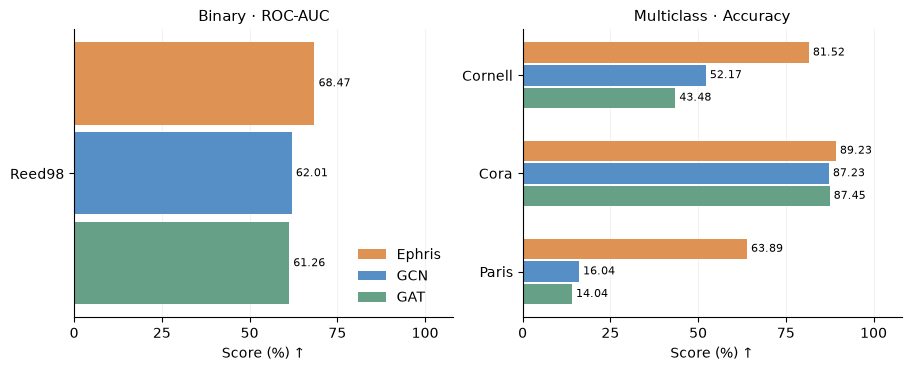

In [6]:
colors = {"Ephris": "#DE9355", "GCN": "#568FC5", "GAT": "#65A087"}
groups = [("ROC-AUC", "Binary · ROC-AUC"), ("Accuracy", "Multiclass · Accuracy")]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), layout="constrained")
for ax, (metric, title) in zip(axes, groups):
    rows = [row for row in summary if row["Metric"] == metric]
    positions = np.arange(len(rows))
    for offset, method in enumerate(methods):
        values = [100 * row[method] for row in rows]
        bars = ax.barh(positions + (offset - 1) * 0.23, values, height=0.21,
                       color=colors[method], label=method)
        ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
    ax.set_yticks(positions, [row["Dataset"] for row in rows])
    ax.invert_yaxis()
    ax.set_xlim(0, 108)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Score (%) ↑")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)
axes[0].legend(loc="lower right", frameon=False)
fig.savefig(export_dir / "performance.png", dpi=180, bbox_inches="tight")
fig.savefig(export_dir / "performance.pdf", bbox_inches="tight")
display(fig)
plt.close(fig)